# Data Preparation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ModuleNotFoundError: No module named 'matplotlib'

In [2]:
water = pd.read_csv('/Users/yudhapratama/Downloads/P_Data_Extract_From_Indonesia_Database_for_Policy_and_Economic_Research (1)/19ddc44d-9c88-4221-b4bb-86e2bf542203_Data.csv',encoding='latin1')
# mun = mun[mun['unit']=='THS_T']
# mun=mun[['geo','TIME_PERIOD','OBS_VALUE']]
# mun = mun.rename(columns={'geo':'cou','TIME_PERIOD':'year','OBS_VALUE':'waste'})
water

,Provinces Name,Provinces Code,Time,Time Code,Household Access to Safe Water (in % of total household) [HOU.H2O.ACSN.ZS],Total Expenditure (in IDR) [EC.XPD.TOTL.CR],Morbidity Rate (in %) [SH.MORB.ZS],Total Area (in Km²) [LND.TOTL.K2],Human Development Index [IDX.HDI],Total Population (in number of people) [SP.POP.TOTL],Total Own Source Revenue/PAD (in IDR) [REV.OSRV.CR],Number of people employed [SL.EMP.TOTL]
0,"Bali, Prop.",ID.BA,1976.0,YR1976,..,..,..,..,..,..,..,..
1,"Bali, Prop.",ID.BA,1977.0,YR1977,..,..,..,..,..,..,..,..
2,"Bali, Prop.",ID.BA,1978.0,YR1978,..,..,..,..,..,..,..,..
3,"Bali, Prop.",ID.BA,1979.0,YR1979,..,..,..,..,..,..,..,..
4,"Bali, Prop.",ID.BA,1980.0,YR1980,..,..,..,..,..,..,..,..
...,...,...,...,...,...,...,...,...,...,...,...,...
11565,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11568,Data from database: Indonesia Database for Pol...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
water.dropna(inplace=True)

Kita sudah menghapus Nan yang bukan bawaan. Bukan data kosong

## Ganti Nama Kolom

In [4]:
kolom = {
    'Provinces Name' : 'kota',
    'Provinces Code' : 'id',
    'Time' : 'yr',
    'Household Access to Safe Water (in % of total household) [HOU.H2O.ACSN.ZS]':'water',
    'Total Expenditure (in IDR) [EC.XPD.TOTL.CR]' : 'expend',
    'Morbidity Rate (in %) [SH.MORB.ZS]' : 'morbid',
    'Total Area (in Km²) [LND.TOTL.K2]' : 'area',
    'Human Development Index [IDX.HDI]' : 'hdi',
    'Total Population (in number of people) [SP.POP.TOTL]':'pop',
    'Total Own Source Revenue/PAD (in IDR) [REV.OSRV.CR]':'pad',
    'Number of people employed [SL.EMP.TOTL]':'employ'  
}

In [5]:
water.rename(columns=kolom,inplace=True)

In [6]:
water.head(100)

,kota,id,yr,Time Code,water,expend,morbid,area,hdi,pop,pad,employ
0,"Bali, Prop.",ID.BA,1976.0,YR1976,..,..,..,..,..,..,..,..
1,"Bali, Prop.",ID.BA,1977.0,YR1977,..,..,..,..,..,..,..,..
2,"Bali, Prop.",ID.BA,1978.0,YR1978,..,..,..,..,..,..,..,..
3,"Bali, Prop.",ID.BA,1979.0,YR1979,..,..,..,..,..,..,..,..
4,"Bali, Prop.",ID.BA,1980.0,YR1980,..,..,..,..,..,..,..,..
...,...,...,...,...,...,...,...,...,...,...,...,...
95,"Bengkulu, Prop.",ID.BE,1981.0,YR1981,..,..,..,..,..,..,..,..
96,"Bengkulu, Prop.",ID.BE,1982.0,YR1982,..,..,..,..,..,..,..,..
97,"Bengkulu, Prop.",ID.BE,1983.0,YR1983,..,..,..,..,..,867335,..,..
98,"Bengkulu, Prop.",ID.BE,1984.0,YR1984,..,..,..,..,..,904352,..,..


## Mengganti jadi nilai Nan

In [7]:
water.replace({'..': np.nan},inplace=True)

In [8]:
water.isna().sum()

kota            0
id              0
yr              0
Time Code       0
water        5812
expend       6996
morbid       5812
area         9339
hdi          8669
pop          3401
pad          5623
employ       8119
dtype: int64

## Menghapus Target

In [9]:
water.dropna(subset=['water'],inplace=True)

In [10]:
water

,kota,id,yr,Time Code,water,expend,morbid,area,hdi,pop,pad,employ
20,"Bali, Prop.",ID.BA,1996.0,YR1996,55.83,NaN,30.961,NaN,70.1,2924400,95779720000,NaN
21,"Bali, Prop.",ID.BA,1997.0,YR1997,60.64,NaN,30.297,NaN,NaN,2902900,102151431000,NaN
22,"Bali, Prop.",ID.BA,1998.0,YR1998,62.6,NaN,29.89,NaN,NaN,2966900,80300937000,NaN
23,"Bali, Prop.",ID.BA,1999.0,YR1999,63.16,NaN,31.313,NaN,65.7,2987000,229742785000,NaN
24,"Bali, Prop.",ID.BA,2000.0,YR2000,63.42,NaN,30.468,5634,NaN,3111402,237915032000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
11560,"Way Kanan, Kab.",ID.LA.WK,2016.0,YR2016,38.022819519043,1180257690465.2,25.0378131866455,NaN,NaN,437530,44346945471.84,NaN
11561,"Way Kanan, Kab.",ID.LA.WK,2017.0,YR2017,17.7903614044189,1350721647447,30.8675670623779,NaN,NaN,441922,49551283407.98,211912
11562,"Way Kanan, Kab.",ID.LA.WK,2018.0,YR2018,27.2429351806641,1501095281556,34.8004684448242,NaN,NaN,446113,56764985088.23,220524
11563,"Way Kanan, Kab.",ID.LA.WK,2019.0,YR2019,34.5243644714355,1401165789733.15,31.2577781677246,NaN,NaN,450109,62353560983.81,238736


In [ ]:
water.isna().sum()

kota            0
id              0
yr              0
Time Code       0
water           0
expend       1221
morbid          2
area         3592
hdi          2899
pop            49
pad           230
employ       2324
dtype: int64

In [12]:
water['area'] = water.groupby('id').area.transform(lambda x : x.fillna(method='ffill').fillna(method='bfill'))
water.head(40)

,kota,id,yr,Time Code,water,expend,morbid,area,hdi,pop,pad,employ
20,"Bali, Prop.",ID.BA,1996.0,YR1996,55.83,NaN,30.961,5634,70.1,2924400,95779720000,NaN
21,"Bali, Prop.",ID.BA,1997.0,YR1997,60.64,NaN,30.297,5634,NaN,2902900,102151431000,NaN
22,"Bali, Prop.",ID.BA,1998.0,YR1998,62.6,NaN,29.89,5634,NaN,2966900,80300937000,NaN
23,"Bali, Prop.",ID.BA,1999.0,YR1999,63.16,NaN,31.313,5634,65.7,2987000,229742785000,NaN
24,"Bali, Prop.",ID.BA,2000.0,YR2000,63.42,NaN,30.468,5634,NaN,3111402,237915032000,NaN
25,"Bali, Prop.",ID.BA,2001.0,YR2001,69.77,568760823939,29.78,5632.86,NaN,3197107.89153548,190521652046,1798222
26,"Bali, Prop.",ID.BA,2002.0,YR2002,68.99,740080737306,30.08,5632.86,67.5,3273502.85046814,465749519228,1774315
27,"Bali, Prop.",ID.BA,2003.0,YR2003,70.59,610785037616,28.265,5632.86,NaN,3448936.74047487,382259828113,1797405
28,"Bali, Prop.",ID.BA,2004.0,YR2004,69.86,664634244815,30.988,5612.86,69.1,3513249.61051473,559689357943,1835165
29,"Bali, Prop.",ID.BA,2005.0,YR2005,72.07,841177978582,33.006,5586.56,69.78,3578538.16696733,742886074752,1895741


In [13]:
from sklearn.impute import KNNImputer

In [14]:
water.isna().sum()

kota            0
id              0
yr              0
Time Code       0
water           0
expend       1221
morbid          2
area          232
hdi          2899
pop            49
pad           230
employ       2324
dtype: int64

In [15]:
imp_knn = KNNImputer(n_neighbors=5, weights="uniform")
water[['expend','pop','pad']] = imp_knn.fit_transform(water[['expend','pop','pad']])

In [16]:
water.describe()

,yr,expend,pop,pad
count,5753.000000,5.753000e+03,5.753000e+03,5.753000e+03
mean,2008.866157,1.463110e+12,1.660169e+06,4.054739e+11
std,7.016260,2.978234e+12,4.445101e+06,1.908792e+12
min,1996.000000,0.000000e+00,1.338500e+04,0.000000e+00
25%,2003.000000,3.669043e+11,2.459980e+05,1.941466e+10
50%,2009.000000,8.149524e+11,7.383830e+05,6.185562e+10
75%,2015.000000,1.580878e+12,1.388000e+06,2.241979e+11
max,2020.000000,6.493836e+13,4.993586e+07,4.570740e+13


In [17]:
water = water[water['area'].notna()]
water.isna().sum()

kota            0
id              0
yr              0
Time Code       0
water           0
expend          0
morbid          2
area            0
hdi          2761
pop             0
pad             0
employ       2249
dtype: int64

In [18]:
water.columns

Index(['kota', 'id', 'yr', 'Time Code', 'water', 'expend', 'morbid', 'area',
       'hdi', 'pop', 'pad', 'employ'],
      dtype='object')

# Data Preparation

In [19]:
water

,kota,id,yr,Time Code,water,expend,morbid,area,hdi,pop,pad,employ
20,"Bali, Prop.",ID.BA,1996.0,YR1996,55.83,1.239521e+12,30.961,5634,70.1,2924400.0,9.577972e+10,NaN
21,"Bali, Prop.",ID.BA,1997.0,YR1997,60.64,1.169236e+12,30.297,5634,NaN,2902900.0,1.021514e+11,NaN
22,"Bali, Prop.",ID.BA,1998.0,YR1998,62.6,1.077836e+12,29.89,5634,NaN,2966900.0,8.030094e+10,NaN
23,"Bali, Prop.",ID.BA,1999.0,YR1999,63.16,1.316615e+12,31.313,5634,65.7,2987000.0,2.297428e+11,NaN
24,"Bali, Prop.",ID.BA,2000.0,YR2000,63.42,1.560726e+12,30.468,5634,NaN,3111402.0,2.379150e+11,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
11560,"Way Kanan, Kab.",ID.LA.WK,2016.0,YR2016,38.022819519043,1.180258e+12,25.0378131866455,3921.63,NaN,437530.0,4.434695e+10,NaN
11561,"Way Kanan, Kab.",ID.LA.WK,2017.0,YR2017,17.7903614044189,1.350722e+12,30.8675670623779,3921.63,NaN,441922.0,4.955128e+10,211912
11562,"Way Kanan, Kab.",ID.LA.WK,2018.0,YR2018,27.2429351806641,1.501095e+12,34.8004684448242,3921.63,NaN,446113.0,5.676499e+10,220524
11563,"Way Kanan, Kab.",ID.LA.WK,2019.0,YR2019,34.5243644714355,1.401166e+12,31.2577781677246,3921.63,NaN,450109.0,6.235356e+10,238736


In [20]:
water['yr'] = pd.to_datetime(water['yr'])
water['yr'] = water['yr'].dt.year

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/1040877225.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  water['yr'] = pd.to_datetime(water['yr'])
/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/1040877225.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  water['yr'] = water['yr'].dt.year


In [21]:
water.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 5521 entries, 20 to 11564
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   kota       5521 non-null   object 
 1   id         5521 non-null   object 
 2   yr         5521 non-null   int64  
 3   Time Code  5521 non-null   object 
 4   water      5521 non-null   object 
 5   expend     5521 non-null   float64
 6   morbid     5519 non-null   object 
 7   area       5521 non-null   object 
 8   hdi        2760 non-null   object 
 9   pop        5521 non-null   float64
 10  pad        5521 non-null   float64
 11  employ     3272 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 560.7+ KB


In [22]:
print(water.dtypes)

kota          object
id            object
yr             int64
Time Code     object
water         object
expend       float64
morbid        object
area          object
hdi           object
pop          float64
pad          float64
employ        object
dtype: object


In [23]:
water['water'] = water.water.astype('float')
water['area'] = water.area.astype('float')
water['morbid'] = water.morbid.astype('float')

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/1023634162.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  water['water'] = water.water.astype('float')
/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/1023634162.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  water['area'] = water.area.astype('float')
/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/1023634162.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataF

In [24]:
water

,kota,id,yr,Time Code,water,expend,morbid,area,hdi,pop,pad,employ
20,"Bali, Prop.",ID.BA,1970,YR1996,55.830000,1.239521e+12,30.961000,5634.00,70.1,2924400.0,9.577972e+10,NaN
21,"Bali, Prop.",ID.BA,1970,YR1997,60.640000,1.169236e+12,30.297000,5634.00,NaN,2902900.0,1.021514e+11,NaN
22,"Bali, Prop.",ID.BA,1970,YR1998,62.600000,1.077836e+12,29.890000,5634.00,NaN,2966900.0,8.030094e+10,NaN
23,"Bali, Prop.",ID.BA,1970,YR1999,63.160000,1.316615e+12,31.313000,5634.00,65.7,2987000.0,2.297428e+11,NaN
24,"Bali, Prop.",ID.BA,1970,YR2000,63.420000,1.560726e+12,30.468000,5634.00,NaN,3111402.0,2.379150e+11,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
11560,"Way Kanan, Kab.",ID.LA.WK,1970,YR2016,38.022820,1.180258e+12,25.037813,3921.63,NaN,437530.0,4.434695e+10,NaN
11561,"Way Kanan, Kab.",ID.LA.WK,1970,YR2017,17.790361,1.350722e+12,30.867567,3921.63,NaN,441922.0,4.955128e+10,211912
11562,"Way Kanan, Kab.",ID.LA.WK,1970,YR2018,27.242935,1.501095e+12,34.800468,3921.63,NaN,446113.0,5.676499e+10,220524
11563,"Way Kanan, Kab.",ID.LA.WK,1970,YR2019,34.524364,1.401166e+12,31.257778,3921.63,NaN,450109.0,6.235356e+10,238736


In [25]:
water[['water','area','morbid','pad','expend']] = water[['water','area','morbid','pad','expend']].round(2)

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/3338644459.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  water[['water','area','morbid','pad','expend']] = water[['water','area','morbid','pad','expend']].round(2)


In [26]:
df = water[~water["kota"].str.contains('Prop.')]
df

,kota,id,yr,Time Code,water,expend,morbid,area,hdi,pop,pad,employ
1550,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1996,12.99,1.679734e+11,17.11,5949.00,64.4,315900.0,9.302870e+08,NaN
1551,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1997,14.60,1.900460e+11,17.54,5949.00,NaN,317600.0,1.448954e+09,NaN
1552,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1998,13.99,1.746915e+11,23.03,5949.00,NaN,318900.0,1.608408e+09,NaN
1553,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1999,8.20,1.659548e+11,15.82,5949.00,NaN,319800.0,1.686854e+09,NaN
1554,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR2000,9.01,1.753945e+11,20.42,5949.00,NaN,370678.0,6.493360e+08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
11560,"Way Kanan, Kab.",ID.LA.WK,1970,YR2016,38.02,1.180258e+12,25.04,3921.63,NaN,437530.0,4.434695e+10,NaN
11561,"Way Kanan, Kab.",ID.LA.WK,1970,YR2017,17.79,1.350722e+12,30.87,3921.63,NaN,441922.0,4.955128e+10,211912
11562,"Way Kanan, Kab.",ID.LA.WK,1970,YR2018,27.24,1.501095e+12,34.80,3921.63,NaN,446113.0,5.676499e+10,220524
11563,"Way Kanan, Kab.",ID.LA.WK,1970,YR2019,34.52,1.401166e+12,31.26,3921.63,NaN,450109.0,6.235356e+10,238736


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4750 entries, 1550 to 11564
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   kota       4750 non-null   object 
 1   id         4750 non-null   object 
 2   yr         4750 non-null   int64  
 3   Time Code  4750 non-null   object 
 4   water      4750 non-null   float64
 5   expend     4750 non-null   float64
 6   morbid     4750 non-null   float64
 7   area       4750 non-null   float64
 8   hdi        2355 non-null   object 
 9   pop        4750 non-null   float64
 10  pad        4750 non-null   float64
 11  employ     2695 non-null   object 
dtypes: float64(6), int64(1), object(5)
memory usage: 482.4+ KB


In [28]:
coba = df.copy
coba()

,kota,id,yr,Time Code,water,expend,morbid,area,hdi,pop,pad,employ
1550,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1996,12.99,1.679734e+11,17.11,5949.00,64.4,315900.0,9.302870e+08,NaN
1551,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1997,14.60,1.900460e+11,17.54,5949.00,NaN,317600.0,1.448954e+09,NaN
1552,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1998,13.99,1.746915e+11,23.03,5949.00,NaN,318900.0,1.608408e+09,NaN
1553,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR1999,8.20,1.659548e+11,15.82,5949.00,NaN,319800.0,1.686854e+09,NaN
1554,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,YR2000,9.01,1.753945e+11,20.42,5949.00,NaN,370678.0,6.493360e+08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
11560,"Way Kanan, Kab.",ID.LA.WK,1970,YR2016,38.02,1.180258e+12,25.04,3921.63,NaN,437530.0,4.434695e+10,NaN
11561,"Way Kanan, Kab.",ID.LA.WK,1970,YR2017,17.79,1.350722e+12,30.87,3921.63,NaN,441922.0,4.955128e+10,211912
11562,"Way Kanan, Kab.",ID.LA.WK,1970,YR2018,27.24,1.501095e+12,34.80,3921.63,NaN,446113.0,5.676499e+10,220524
11563,"Way Kanan, Kab.",ID.LA.WK,1970,YR2019,34.52,1.401166e+12,31.26,3921.63,NaN,450109.0,6.235356e+10,238736


In [29]:
df['Time Code'] = df['Time Code'].str.replace('YR','')

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/1748034157.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Time Code'] = df['Time Code'].str.replace('YR','')


In [30]:
df.rename(columns={'Time Code':'year'},inplace=True)

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/4054945869.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={'Time Code':'year'},inplace=True)


In [31]:
df

,kota,id,yr,year,water,expend,morbid,area,hdi,pop,pad,employ
1550,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1996,12.99,1.679734e+11,17.11,5949.00,64.4,315900.0,9.302870e+08,NaN
1551,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1997,14.60,1.900460e+11,17.54,5949.00,NaN,317600.0,1.448954e+09,NaN
1552,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1998,13.99,1.746915e+11,23.03,5949.00,NaN,318900.0,1.608408e+09,NaN
1553,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1999,8.20,1.659548e+11,15.82,5949.00,NaN,319800.0,1.686854e+09,NaN
1554,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,2000,9.01,1.753945e+11,20.42,5949.00,NaN,370678.0,6.493360e+08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
11560,"Way Kanan, Kab.",ID.LA.WK,1970,2016,38.02,1.180258e+12,25.04,3921.63,NaN,437530.0,4.434695e+10,NaN
11561,"Way Kanan, Kab.",ID.LA.WK,1970,2017,17.79,1.350722e+12,30.87,3921.63,NaN,441922.0,4.955128e+10,211912
11562,"Way Kanan, Kab.",ID.LA.WK,1970,2018,27.24,1.501095e+12,34.80,3921.63,NaN,446113.0,5.676499e+10,220524
11563,"Way Kanan, Kab.",ID.LA.WK,1970,2019,34.52,1.401166e+12,31.26,3921.63,NaN,450109.0,6.235356e+10,238736


In [32]:
df[df['kota'].str.contains("Bandung")]

,kota,id,yr,year,water,expend,morbid,area,hdi,pop,pad,employ
3271,"Bandung Barat, Kab.",ID.JR.BB,1970,2007,48.01,1.752049e+12,23.38,1305.77,72.28629,1400284.0,6.139371e+11,NaN
3272,"Bandung Barat, Kab.",ID.JR.BB,1970,2008,47.85,1.022067e+12,24.55,1305.77,72.65015,1419445.0,3.361747e+10,527311
3273,"Bandung Barat, Kab.",ID.JR.BB,1970,2009,56.60,8.491454e+11,22.05,1305.77,72.99,1438227.0,3.996436e+10,561020
3274,"Bandung Barat, Kab.",ID.JR.BB,1970,2010,61.77,1.010276e+12,19.70,1305.77,73.35,1522076.0,5.036767e+10,509565
3275,"Bandung Barat, Kab.",ID.JR.BB,1970,2011,47.23,1.251596e+12,20.62,1305.77,73.8,1545118.0,9.460617e+10,597633
...,...,...,...,...,...,...,...,...,...,...,...,...
3370,"Bandung, Kota",ID.JR.BN,1970,2016,87.92,5.830414e+12,26.99,167.67,NaN,2490622.0,2.152756e+12,NaN
3371,"Bandung, Kota",ID.JR.BN,1970,2017,92.49,5.541718e+12,33.34,167.67,NaN,2497938.0,2.578457e+12,1116529
3372,"Bandung, Kota",ID.JR.BN,1970,2018,93.30,6.114449e+12,33.86,167.67,NaN,2503708.0,2.571592e+12,1107986
3373,"Bandung, Kota",ID.JR.BN,1970,2019,94.89,6.312147e+12,31.37,167.67,NaN,2507888.0,2.548259e+12,1183193


In [33]:
# df.drop(columns=['tingkat'],axis=1,inplace=True)
df[['daerah','tingkat']] = df['kota'].str.split(',', expand=True)
df['tingkat'] = df['tingkat'].str.strip()
df['daerah'] = df['daerah'].str.strip()
df

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/3435515613.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['daerah','tingkat']] = df['kota'].str.split(',', expand=True)
/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/3435515613.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['daerah','tingkat']] = df['kota'].str.split(',', expand=True)
/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/3435515613.py:3: SettingWithCopyWarning: 
A value is trying

,kota,id,yr,year,water,expend,morbid,area,hdi,pop,pad,employ,daerah,tingkat
1550,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1996,12.99,1.679734e+11,17.11,5949.00,64.4,315900.0,9.302870e+08,NaN,Bengkulu Selatan,Kab.
1551,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1997,14.60,1.900460e+11,17.54,5949.00,NaN,317600.0,1.448954e+09,NaN,Bengkulu Selatan,Kab.
1552,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1998,13.99,1.746915e+11,23.03,5949.00,NaN,318900.0,1.608408e+09,NaN,Bengkulu Selatan,Kab.
1553,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,1999,8.20,1.659548e+11,15.82,5949.00,NaN,319800.0,1.686854e+09,NaN,Bengkulu Selatan,Kab.
1554,"Bengkulu Selatan, Kab.",ID.BE.BS,1970,2000,9.01,1.753945e+11,20.42,5949.00,NaN,370678.0,6.493360e+08,NaN,Bengkulu Selatan,Kab.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11560,"Way Kanan, Kab.",ID.LA.WK,1970,2016,38.02,1.180258e+12,25.04,3921.63,NaN,437530.0,4.434695e+10,NaN,Way Kanan,Kab.
11561,"Way Kanan, Kab.",ID.LA.WK,1970,2017,17.79,1.350722e+12,30.87,3921.63,NaN,441922.0,4.955128e+10,211912,Way Kanan,Kab.
11562,"Way Kanan, Kab.",ID.LA.WK,1970,2018,27.24,1.501095e+12,34.80,3921.63,NaN,446113.0,5.676499e+10,220524,Way Kanan,Kab.
11563,"Way Kanan, Kab.",ID.LA.WK,1970,2019,34.52,1.401166e+12,31.26,3921.63,NaN,450109.0,6.235356e+10,238736,Way Kanan,Kab.


In [34]:
# import plotly.express as px
# import plotly.graph_objects as go

# fig = go.Figure([go.Scatter(name = 'true',x=df['year'], y=df['water'])
# fig.update_xaxes(rangeslider_visible=True)
# fig.show()

In [35]:
df.drop(columns=['hdi','employ'],axis=1,inplace=True)

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/2360314179.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['hdi','employ'],axis=1,inplace=True)


In [36]:
df.drop(columns=['kota','yr'],axis=1,inplace=True)
df

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/2329617949.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['kota','yr'],axis=1,inplace=True)


,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
1550,ID.BE.BS,1996,12.99,1.679734e+11,17.11,5949.00,315900.0,9.302870e+08,Bengkulu Selatan,Kab.
1551,ID.BE.BS,1997,14.60,1.900460e+11,17.54,5949.00,317600.0,1.448954e+09,Bengkulu Selatan,Kab.
1552,ID.BE.BS,1998,13.99,1.746915e+11,23.03,5949.00,318900.0,1.608408e+09,Bengkulu Selatan,Kab.
1553,ID.BE.BS,1999,8.20,1.659548e+11,15.82,5949.00,319800.0,1.686854e+09,Bengkulu Selatan,Kab.
1554,ID.BE.BS,2000,9.01,1.753945e+11,20.42,5949.00,370678.0,6.493360e+08,Bengkulu Selatan,Kab.
...,...,...,...,...,...,...,...,...,...,...
11560,ID.LA.WK,2016,38.02,1.180258e+12,25.04,3921.63,437530.0,4.434695e+10,Way Kanan,Kab.
11561,ID.LA.WK,2017,17.79,1.350722e+12,30.87,3921.63,441922.0,4.955128e+10,Way Kanan,Kab.
11562,ID.LA.WK,2018,27.24,1.501095e+12,34.80,3921.63,446113.0,5.676499e+10,Way Kanan,Kab.
11563,ID.LA.WK,2019,34.52,1.401166e+12,31.26,3921.63,450109.0,6.235356e+10,Way Kanan,Kab.


In [37]:
df.describe()

,water,expend,morbid,area,pop,pad
count,4750.000000,4.750000e+03,4750.000000,4750.000000,4.750000e+03,4.750000e+03
mean,54.858373,9.749035e+11,28.958404,4160.140455,7.540481e+05,1.354848e+11
std,21.821467,9.356403e+11,7.517717,7618.078225,7.110925e+05,3.013033e+11
min,0.940000,0.000000e+00,6.190000,12.000000,1.338500e+04,0.000000e+00
25%,38.410000,3.180296e+11,23.870000,775.987500,2.181388e+05,1.605890e+10
50%,55.125000,6.993678e+11,28.595000,1521.880000,5.733555e+05,4.792337e+10
75%,71.987500,1.288502e+12,33.660000,3921.630000,1.039295e+06,1.398324e+11
max,100.000000,9.162656e+12,64.210000,91027.000000,6.398000e+06,5.381920e+12


# Exploratory Data Analysis

/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use eith

Text(0.5, 1.0, 'Distribusi data dari Penerimaan Asli Daerah')

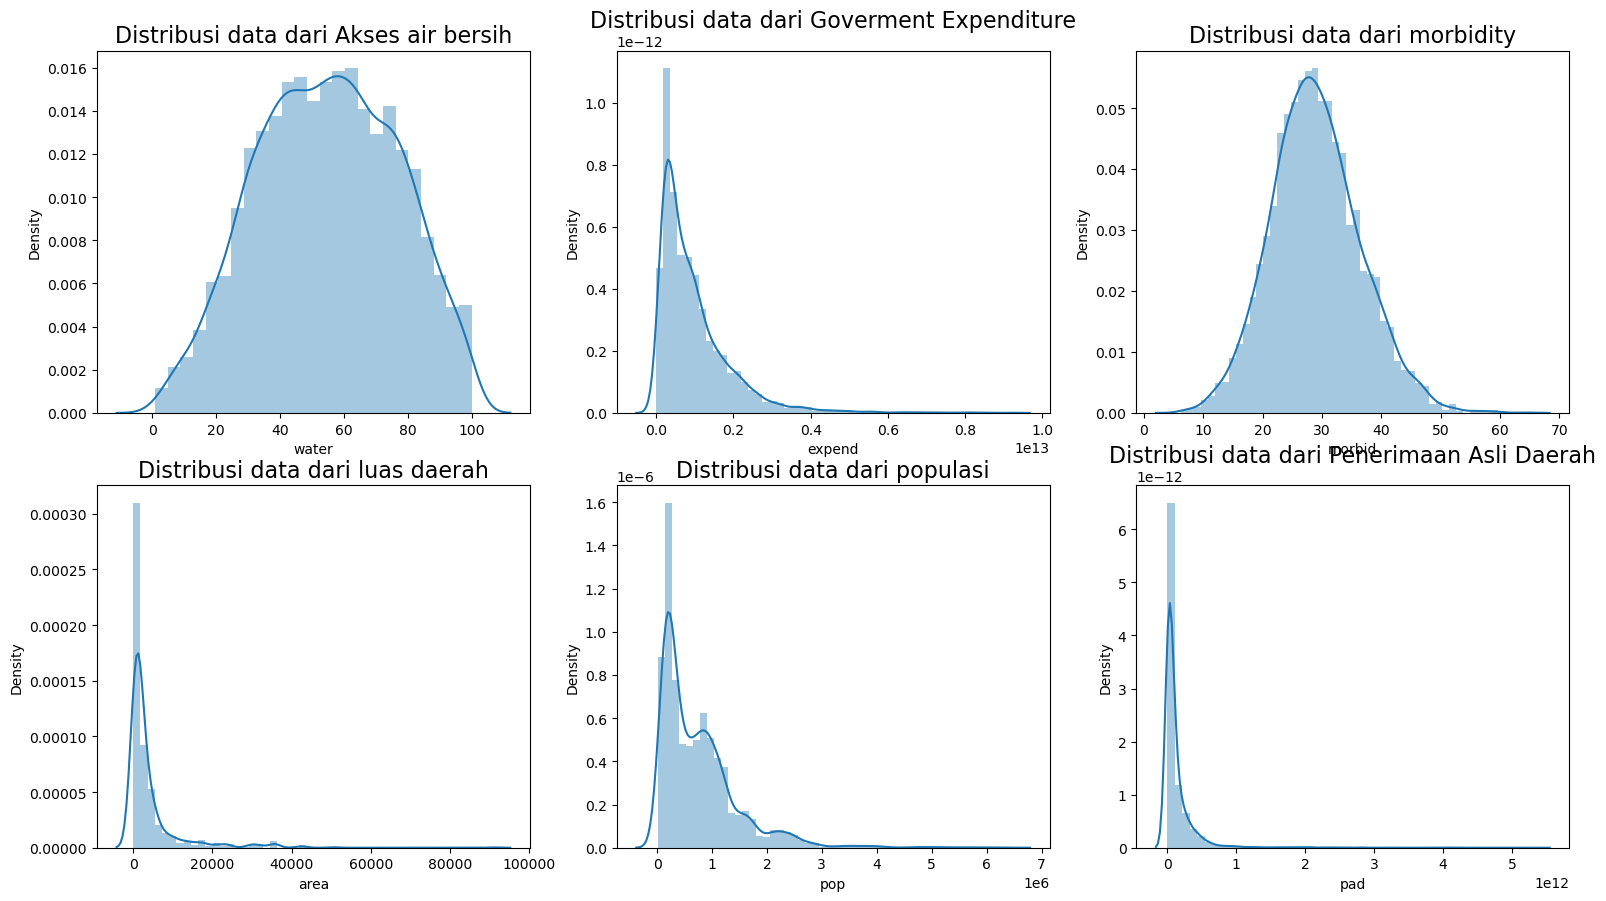

In [38]:
plt.figure(figsize=(19, 16))
plt.subplot(3,3,1)
sns.distplot(df['water'])
plt.title('Distribusi data dari Akses air bersih', size=16)

plt.subplot(3,3,2)
sns.distplot(df['expend'])
plt.title('Distribusi data dari Goverment Expenditure', size=16)

plt.subplot(3,3,3)
sns.distplot(df['morbid'])
plt.title('Distribusi data dari morbidity', size=16)

plt.subplot(3,3,4)
sns.distplot(df['area'])
plt.title('Distribusi data dari luas daerah', size=16)

plt.subplot(3,3,5)
sns.distplot(df['pop'])
plt.title('Distribusi data dari populasi', size=16)

plt.subplot(3,3,6)
sns.distplot(df['pad'])
plt.title('Distribusi data dari Penerimaan Asli Daerah', size=16)

Dilihat dari distribusi datanya, ternyata beberap feature tidak terdistribusi normal, yaitu pad, pop, area dan expend. Sedangkan water dan morbidity terdistribusi normal

## Descriptive Statistics

In [39]:
df.describe()

,water,expend,morbid,area,pop,pad
count,4750.000000,4.750000e+03,4750.000000,4750.000000,4.750000e+03,4.750000e+03
mean,54.858373,9.749035e+11,28.958404,4160.140455,7.540481e+05,1.354848e+11
std,21.821467,9.356403e+11,7.517717,7618.078225,7.110925e+05,3.013033e+11
min,0.940000,0.000000e+00,6.190000,12.000000,1.338500e+04,0.000000e+00
25%,38.410000,3.180296e+11,23.870000,775.987500,2.181388e+05,1.605890e+10
50%,55.125000,6.993678e+11,28.595000,1521.880000,5.733555e+05,4.792337e+10
75%,71.987500,1.288502e+12,33.660000,3921.630000,1.039295e+06,1.398324e+11
max,100.000000,9.162656e+12,64.210000,91027.000000,6.398000e+06,5.381920e+12


In [40]:
df[(df['expend']==0)]

,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
8271,ID.KB.SE,2012,21.18,0.0,30.31,5444.2,187310.0,1.836491e+10,Sekadau,Kab.


In [41]:
df[df['daerah']=='Sekadau']

,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
8264,ID.KB.SE,2005,9.25,9.683978e+10,29.64,5474.2,172042.0,7.657753e+08,Sekadau,Kab.
8265,ID.KB.SE,2006,21.54,2.300649e+11,32.62,5474.2,173095.0,3.747079e+09,Sekadau,Kab.
8266,ID.KB.SE,2007,26.24,6.932278e+11,32.86,5474.2,175529.0,7.517531e+10,Sekadau,Kab.
8267,ID.KB.SE,2008,16.71,5.126990e+11,39.59,5444.2,178129.0,7.594108e+09,Sekadau,Kab.
8268,ID.KB.SE,2009,18.07,5.075613e+11,40.95,5444.2,180649.0,1.515373e+10,Sekadau,Kab.
8269,ID.KB.SE,2010,25.21,4.393296e+11,41.22,5444.2,182201.0,1.199716e+10,Sekadau,Kab.
8270,ID.KB.SE,2011,16.18,4.327618e+11,32.20,5444.2,184635.0,1.976784e+10,Sekadau,Kab.
8271,ID.KB.SE,2012,21.18,0.000000e+00,30.31,5444.2,187310.0,1.836491e+10,Sekadau,Kab.
8272,ID.KB.SE,2013,31.84,5.830779e+11,33.49,5444.2,190048.0,3.554666e+10,Sekadau,Kab.
8273,ID.KB.SE,2014,28.26,6.318695e+11,26.62,5444.2,191797.0,3.444670e+10,Sekadau,Kab.


In [42]:
df[(df['pad']==0)]

,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
3810,ID.JR.CE,2006,79.38,4.041104e+11,24.78,37.36,318457.000000,0.0,Cirebon,Kota
5610,ID.JT.SM,2006,63.76,2.257397e+11,23.45,950.21,889524.000000,0.0,Semarang,Kab.
5880,ID.JT.TE,2006,95.39,2.918122e+11,12.53,35.38,239160.000000,0.0,Tegal,Kota
9120,ID.KT.GM,2006,21.93,2.257397e+11,34.76,10805.00,84396.000000,0.0,Gunung Mas,Kab.
10598,ID.KR.BA,1999,51.39,2.257397e+11,12.99,612.00,569312.432478,0.0,Batam,Kota


In [43]:
df[df['daerah']=='Semarang']

,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
5600,ID.JT.SM,1996,47.56,2.320560e+11,25.69,982.00,812400.0,8.152724e+09,Semarang,Kab.
5601,ID.JT.SM,1997,44.89,2.458398e+11,22.14,982.00,815200.0,9.635262e+09,Semarang,Kab.
5602,ID.JT.SM,1998,51.85,2.694998e+11,25.27,982.00,817600.0,1.121762e+10,Semarang,Kab.
5603,ID.JT.SM,1999,51.66,4.724064e+11,32.12,982.00,819500.0,1.206929e+10,Semarang,Kab.
5604,ID.JT.SM,2000,52.93,6.837399e+11,34.08,982.00,833214.0,4.874141e+10,Semarang,Kab.
5605,ID.JT.SM,2001,58.92,2.300897e+11,23.62,950.21,836334.0,1.892318e+10,Semarang,Kab.
5606,ID.JT.SM,2002,57.92,2.830786e+11,24.79,950.21,839512.0,3.005862e+10,Semarang,Kab.
5607,ID.JT.SM,2003,50.35,3.577696e+11,21.77,950.21,842647.0,4.026971e+10,Semarang,Kab.
5608,ID.JT.SM,2004,57.54,3.635699e+11,25.33,950.21,888430.0,4.463464e+10,Semarang,Kab.
5609,ID.JT.SM,2005,62.77,3.736693e+11,17.84,950.21,894481.0,5.651182e+10,Semarang,Kab.


Ada 6 Observasi yang pad dan expend nya 0. Ini tidak masuk akal. Maka saya coba untuk melakukan Itrative Imputer. Saya mengahapus dulu nilai 0 dan kemudian diganti dengan nan yang akan dimasukan imputer berdasarkan regresi

In [44]:
df[['expend','pad']] = df[['expend','pad']].replace({0: np.nan})
df.isna().sum()

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/1253899327.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['expend','pad']] = df[['expend','pad']].replace({0: np.nan})


id         0
year       0
water      0
expend     1
morbid     0
area       0
pop        0
pad        5
daerah     0
tingkat    0
dtype: int64

In [45]:
imp_knn = KNNImputer(n_neighbors=5, weights="uniform")
df[['expend','pop','pad']] = imp_knn.fit_transform(df[['expend','pop','pad']])

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/250787512.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['expend','pop','pad']] = imp_knn.fit_transform(df[['expend','pop','pad']])


In [46]:
df.describe()

,water,expend,morbid,area,pop,pad
count,4750.000000,4.750000e+03,4750.000000,4750.000000,4.750000e+03,4.750000e+03
mean,54.858373,9.749613e+11,28.958404,4160.140455,7.540481e+05,1.355085e+11
std,21.821467,9.355885e+11,7.517717,7618.078225,7.110925e+05,3.012936e+11
min,0.940000,2.303085e+09,6.190000,12.000000,1.338500e+04,3.985110e+08
25%,38.410000,3.180296e+11,23.870000,775.987500,2.181388e+05,1.615406e+10
50%,55.125000,6.993678e+11,28.595000,1521.880000,5.733555e+05,4.792337e+10
75%,71.987500,1.288502e+12,33.660000,3921.630000,1.039295e+06,1.398324e+11
max,100.000000,9.162656e+12,64.210000,91027.000000,6.398000e+06,5.381920e+12


In [47]:
df.isna().sum()

id         0
year       0
water      0
expend     0
morbid     0
area       0
pop        0
pad        0
daerah     0
tingkat    0
dtype: int64

In [48]:
df.to_csv('air.csv')

In [49]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [50]:
imp_iter = IterativeImputer(max_iter=10, random_state=0)
df[['expend','pad']] = imp_iter.fit_transform(df[['expend','pad']])

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/2672206447.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['expend','pad']] = imp_iter.fit_transform(df[['expend','pad']])


In [51]:
df.isna().sum()

id         0
year       0
water      0
expend     0
morbid     0
area       0
pop        0
pad        0
daerah     0
tingkat    0
dtype: int64

In [52]:
df[df['daerah']=='Sekadau']

,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
8264,ID.KB.SE,2005,9.25,9.683978e+10,29.64,5474.2,172042.0,7.657753e+08,Sekadau,Kab.
8265,ID.KB.SE,2006,21.54,2.300649e+11,32.62,5474.2,173095.0,3.747079e+09,Sekadau,Kab.
8266,ID.KB.SE,2007,26.24,6.932278e+11,32.86,5474.2,175529.0,7.517531e+10,Sekadau,Kab.
8267,ID.KB.SE,2008,16.71,5.126990e+11,39.59,5444.2,178129.0,7.594108e+09,Sekadau,Kab.
8268,ID.KB.SE,2009,18.07,5.075613e+11,40.95,5444.2,180649.0,1.515373e+10,Sekadau,Kab.
8269,ID.KB.SE,2010,25.21,4.393296e+11,41.22,5444.2,182201.0,1.199716e+10,Sekadau,Kab.
8270,ID.KB.SE,2011,16.18,4.327618e+11,32.20,5444.2,184635.0,1.976784e+10,Sekadau,Kab.
8271,ID.KB.SE,2012,21.18,2.746283e+11,30.31,5444.2,187310.0,1.836491e+10,Sekadau,Kab.
8272,ID.KB.SE,2013,31.84,5.830779e+11,33.49,5444.2,190048.0,3.554666e+10,Sekadau,Kab.
8273,ID.KB.SE,2014,28.26,6.318695e+11,26.62,5444.2,191797.0,3.444670e+10,Sekadau,Kab.


In [53]:
df

,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
1550,ID.BE.BS,1996,12.99,1.679734e+11,17.11,5949.00,315900.0,9.302870e+08,Bengkulu Selatan,Kab.
1551,ID.BE.BS,1997,14.60,1.900460e+11,17.54,5949.00,317600.0,1.448954e+09,Bengkulu Selatan,Kab.
1552,ID.BE.BS,1998,13.99,1.746915e+11,23.03,5949.00,318900.0,1.608408e+09,Bengkulu Selatan,Kab.
1553,ID.BE.BS,1999,8.20,1.659548e+11,15.82,5949.00,319800.0,1.686854e+09,Bengkulu Selatan,Kab.
1554,ID.BE.BS,2000,9.01,1.753945e+11,20.42,5949.00,370678.0,6.493360e+08,Bengkulu Selatan,Kab.
...,...,...,...,...,...,...,...,...,...,...
11560,ID.LA.WK,2016,38.02,1.180258e+12,25.04,3921.63,437530.0,4.434695e+10,Way Kanan,Kab.
11561,ID.LA.WK,2017,17.79,1.350722e+12,30.87,3921.63,441922.0,4.955128e+10,Way Kanan,Kab.
11562,ID.LA.WK,2018,27.24,1.501095e+12,34.80,3921.63,446113.0,5.676499e+10,Way Kanan,Kab.
11563,ID.LA.WK,2019,34.52,1.401166e+12,31.26,3921.63,450109.0,6.235356e+10,Way Kanan,Kab.


## Opening Data Bersih

In [54]:
df = pd.read_csv('/Users/yudhapratama/Documents/Bahan Kuliah/UrbanAnalytics/air.csv')
df

,Unnamed: 0,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
0,1550,ID.BE.BS,1996,12.99,1.679734e+11,17.11,5949.00,315900.0,9.302870e+08,Bengkulu Selatan,Kab.
1,1551,ID.BE.BS,1997,14.60,1.900460e+11,17.54,5949.00,317600.0,1.448954e+09,Bengkulu Selatan,Kab.
2,1552,ID.BE.BS,1998,13.99,1.746915e+11,23.03,5949.00,318900.0,1.608408e+09,Bengkulu Selatan,Kab.
3,1553,ID.BE.BS,1999,8.20,1.659548e+11,15.82,5949.00,319800.0,1.686854e+09,Bengkulu Selatan,Kab.
4,1554,ID.BE.BS,2000,9.01,1.753945e+11,20.42,5949.00,370678.0,6.493360e+08,Bengkulu Selatan,Kab.
...,...,...,...,...,...,...,...,...,...,...,...
4745,11560,ID.LA.WK,2016,38.02,1.180258e+12,25.04,3921.63,437530.0,4.434695e+10,Way Kanan,Kab.
4746,11561,ID.LA.WK,2017,17.79,1.350722e+12,30.87,3921.63,441922.0,4.955128e+10,Way Kanan,Kab.
4747,11562,ID.LA.WK,2018,27.24,1.501095e+12,34.80,3921.63,446113.0,5.676499e+10,Way Kanan,Kab.
4748,11563,ID.LA.WK,2019,34.52,1.401166e+12,31.26,3921.63,450109.0,6.235356e+10,Way Kanan,Kab.


In [55]:
df

,Unnamed: 0,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat
0,1550,ID.BE.BS,1996,12.99,1.679734e+11,17.11,5949.00,315900.0,9.302870e+08,Bengkulu Selatan,Kab.
1,1551,ID.BE.BS,1997,14.60,1.900460e+11,17.54,5949.00,317600.0,1.448954e+09,Bengkulu Selatan,Kab.
2,1552,ID.BE.BS,1998,13.99,1.746915e+11,23.03,5949.00,318900.0,1.608408e+09,Bengkulu Selatan,Kab.
3,1553,ID.BE.BS,1999,8.20,1.659548e+11,15.82,5949.00,319800.0,1.686854e+09,Bengkulu Selatan,Kab.
4,1554,ID.BE.BS,2000,9.01,1.753945e+11,20.42,5949.00,370678.0,6.493360e+08,Bengkulu Selatan,Kab.
...,...,...,...,...,...,...,...,...,...,...,...
4745,11560,ID.LA.WK,2016,38.02,1.180258e+12,25.04,3921.63,437530.0,4.434695e+10,Way Kanan,Kab.
4746,11561,ID.LA.WK,2017,17.79,1.350722e+12,30.87,3921.63,441922.0,4.955128e+10,Way Kanan,Kab.
4747,11562,ID.LA.WK,2018,27.24,1.501095e+12,34.80,3921.63,446113.0,5.676499e+10,Way Kanan,Kab.
4748,11563,ID.LA.WK,2019,34.52,1.401166e+12,31.26,3921.63,450109.0,6.235356e+10,Way Kanan,Kab.


## Checking for balance, 

In [56]:
df['daerah'].value_counts(ascending=True)

Pesawaran          12
Kubu Raya          12
Tana Tidung        12
Bandung Barat      14
Gorontalo Utara    14
                   ..
Semarang           50
Bandung            50
Cirebon            50
Kediri             50
Probolinggo        50
Name: daerah, Length: 188, dtype: int64

In [57]:
df['year'].value_counts(ascending=True)

1996    148
1997    148
1998    148
1999    149
2000    150
2001    170
2002    171
2003    171
2004    186
2006    201
2005    202
2008    205
2007    205
2019    208
2009    208
2010    208
2011    208
2012    208
2013    208
2014    208
2015    208
2016    208
2017    208
2018    208
2020    208
Name: year, dtype: int64

In [58]:
df['tingkat'].value_counts(ascending=True)

Kota     974
Kab.    3776
Name: tingkat, dtype: int64

## Membuat Feature Baru

In [59]:
df.columns

Index(['Unnamed: 0', 'id', 'year', 'water', 'expend', 'morbid', 'area', 'pop',
       'pad', 'daerah', 'tingkat'],
      dtype='object')

In [60]:
df['logpop'] = np.log(df['pop'])
df['logpad'] = np.log(df['pad'])
df['logarea'] = np.log(df['area'])

/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/categorical.py:82: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  plot_data = [np.asarray(s, float) for k, s in iter_data]


<Axes: >

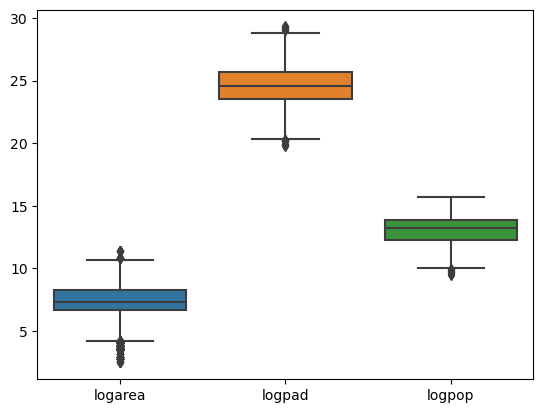

In [61]:
sns.boxplot(data=df[['logarea', "logpad",'logpop']], orient="v")

/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use eith

Text(0.5, 1.0, 'Distribusi data dari log area')

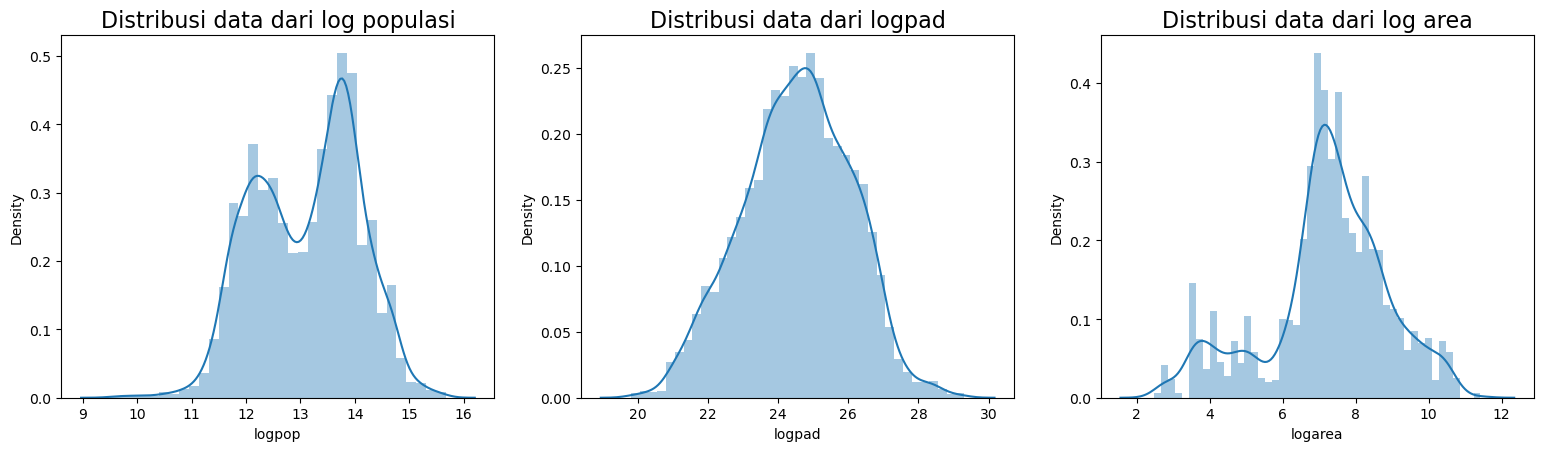

In [62]:
plt.figure(figsize=(19, 16))
plt.subplot(3,3,1)
sns.distplot(df['logpop'])
plt.title('Distribusi data dari log populasi', size=16)

plt.subplot(3,3,2)
sns.distplot(df['logpad'])
plt.title('Distribusi data dari logpad', size=16)

plt.subplot(3,3,3)
sns.distplot(df['logarea'])
plt.title('Distribusi data dari log area', size=16)

## Korelasi Data

/var/folders/gn/wnh0cvb12rgb1y0ptnlzw6280000gn/T/ipykernel_36338/2206821848.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr = df.corr(method='spearman')


<Axes: >

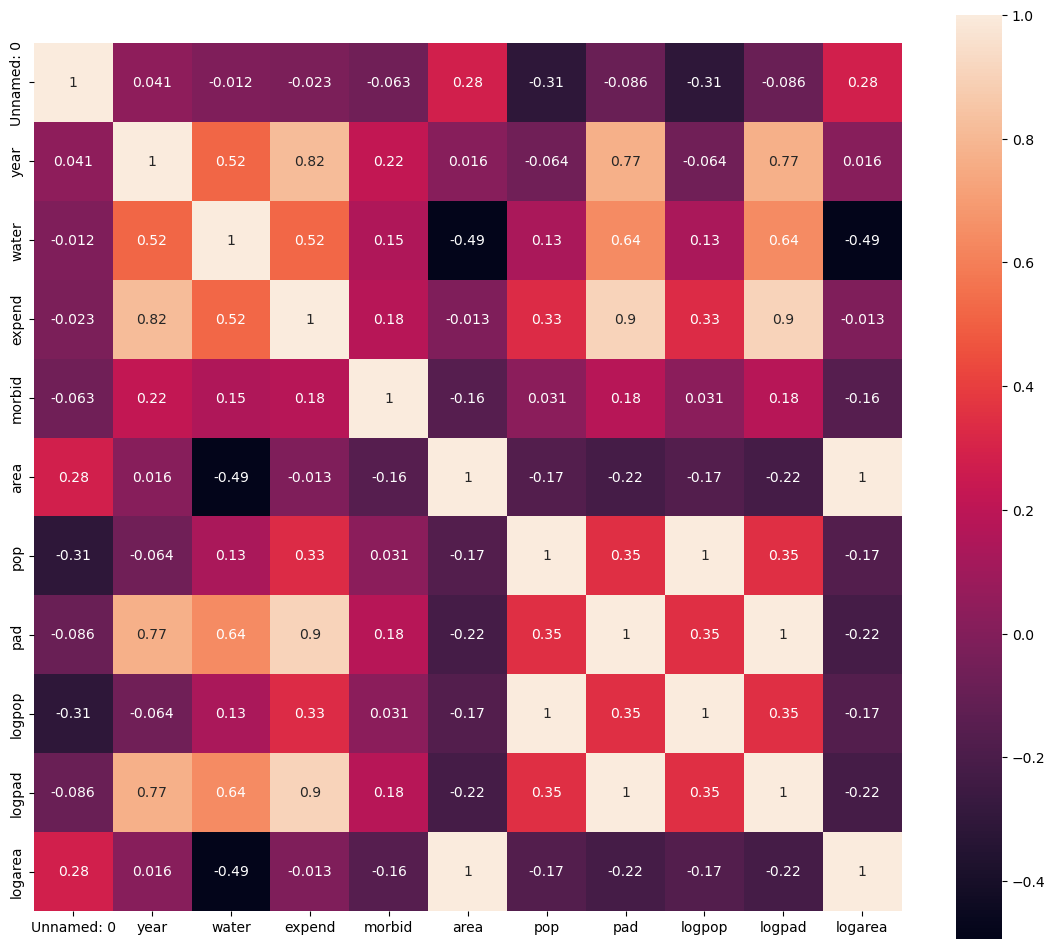

In [63]:
plt.figure(figsize=(14,12))
corr = df.corr(method='spearman')
sns.heatmap(corr, annot=True,square=True)

# Outlier Detection

/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/categorical.py:82: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  plot_data = [np.asarray(s, float) for k, s in iter_data]


<Axes: >

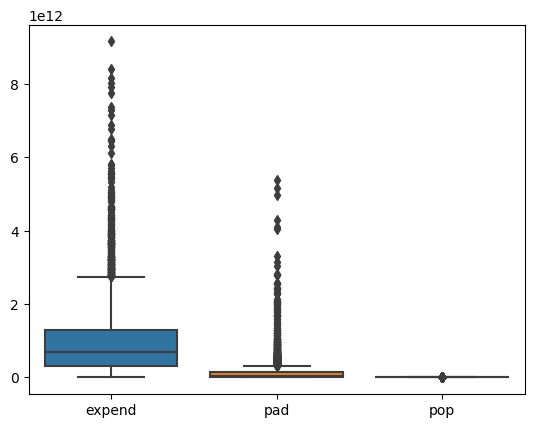

In [64]:
sns.boxplot(data=df[["expend", "pad",'pop']], orient="v")

/Users/yudhapratama/anaconda3/envs/notebook/lib/python3.11/site-packages/seaborn/categorical.py:82: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  plot_data = [np.asarray(s, float) for k, s in iter_data]


<Axes: >

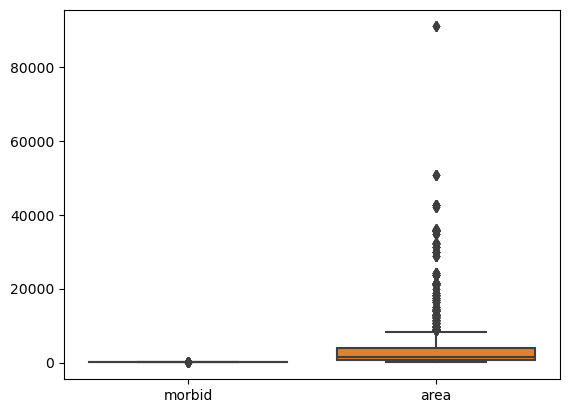

In [65]:
sns.boxplot(data=df[["morbid",'area']], orient="v")

In [66]:
#Membuat kolom baru untuk mengkasifikasikan kota berdasarkan penduduk
kondisi = [
    (df['pop'] <= 100000),
    (df['pop'] > 100000) & (df['pop'] <= 500000),
    (df['pop'] > 500000) & (df['pop'] <= 1000000),
    (df['pop'] > 1000000)
    ]

# create a list of the values we want to assign for each condition
hasil = ['Kota Kecil', 'Kota Sedang', 'Kota Besar', 'Metropolitan']

# create a new column and use np.select to assign values to it using our lists as arguments
df['status'] = np.select(kondisi, hasil)

# display updated DataFrame
df.head()

,Unnamed: 0,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat,logpop,logpad,logarea,status
0,1550,ID.BE.BS,1996,12.99,1.679734e+11,17.11,5949.0,315900.0,9.302870e+08,Bengkulu Selatan,Kab.,12.663181,20.651004,8.690978,Kota Sedang
1,1551,ID.BE.BS,1997,14.60,1.900460e+11,17.54,5949.0,317600.0,1.448954e+09,Bengkulu Selatan,Kab.,12.668548,21.094108,8.690978,Kota Sedang
2,1552,ID.BE.BS,1998,13.99,1.746915e+11,23.03,5949.0,318900.0,1.608408e+09,Bengkulu Selatan,Kab.,12.672633,21.198511,8.690978,Kota Sedang
3,1553,ID.BE.BS,1999,8.20,1.659548e+11,15.82,5949.0,319800.0,1.686854e+09,Bengkulu Selatan,Kab.,12.675451,21.246131,8.690978,Kota Sedang
4,1554,ID.BE.BS,2000,9.01,1.753945e+11,20.42,5949.0,370678.0,6.493360e+08,Bengkulu Selatan,Kab.,12.823089,20.291461,8.690978,Kota Sedang


In [67]:
print(df.groupby('status')['id'].nunique())

status
Kota Besar       77
Kota Kecil       19
Kota Sedang     108
Metropolitan     68
Name: id, dtype: int64


Peraturan yang mengatur pengklasifikasian kota berdasarkan jumlah penduduk di Indonesia adalah Peraturan Menteri Dalam Negeri (Permendagri) Nomor 137 Tahun 2017 tentang Klasifikasi dan Kodefikasi Wilayah Administrasi Pemerintahan. Permendagri ini menetapkan bahwa kota-kota di Indonesia dikelompokkan menjadi 4 kelas berdasarkan jumlah penduduknya, yaitu:

Kelas I: Kota dengan jumlah penduduk di atas 1 juta jiwa

Kelas II: Kota dengan jumlah penduduk antara 500 ribu hingga 1 juta jiwa

Kelas III: Kota dengan jumlah penduduk antara 100 ribu hingga 500 ribu jiwa

Kelas IV: Kota dengan jumlah penduduk di bawah 100 ribu jiwa


In [68]:
df[df['status']=='Metropolitan']

,Unnamed: 0,id,year,water,expend,morbid,area,pop,pad,daerah,tingkat,logpop,logpad,logarea,status
201,2022,ID.YO.BA,2018,76.44,2.165652e+12,31.85,508.13,1006692.0,4.626540e+11,Bantul,Kab.,13.822180,26.860245,6.230737,Metropolitan
202,2023,ID.YO.BA,2019,73.22,2.283585e+12,36.94,508.13,1018402.0,5.059295e+11,Bantul,Kab.,13.833745,26.949663,6.230737,Metropolitan
203,2024,ID.YO.BA,2020,81.37,2.093719e+12,38.69,508.13,1029997.0,4.796108e+11,Bantul,Kab.,13.845066,26.896241,6.230737,Metropolitan
264,2145,ID.YO.SL,2006,60.53,6.097654e+11,46.51,574.82,1013178.0,9.071010e+10,Sleman,Kab.,13.828602,25.230934,6.354057,Metropolitan
265,2146,ID.YO.SL,2007,74.70,2.345891e+11,36.39,574.82,1026767.0,8.231896e+11,Sleman,Kab.,13.841926,27.436452,6.354057,Metropolitan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4632,11114,ID.LA.LI,2020,65.39,2.129426e+12,33.58,5325.03,1051994.0,1.578104e+11,Lampung Timur,Kab.,13.866198,25.784660,8.580174,Metropolitan
4633,11135,ID.LA.LU,1996,19.64,1.979107e+11,22.47,2725.87,1654700.0,3.067415e+09,Lampung Utara,Kab.,14.319130,21.844101,7.910543,Metropolitan
4634,11136,ID.LA.LU,1997,10.20,1.619486e+11,20.05,2725.87,1699900.0,2.283810e+09,Lampung Utara,Kab.,14.346080,21.549111,7.910543,Metropolitan
4635,11137,ID.LA.LU,1998,22.92,2.020444e+11,20.05,2725.87,1744000.0,2.471179e+09,Lampung Utara,Kab.,14.371692,21.627961,7.910543,Metropolitan


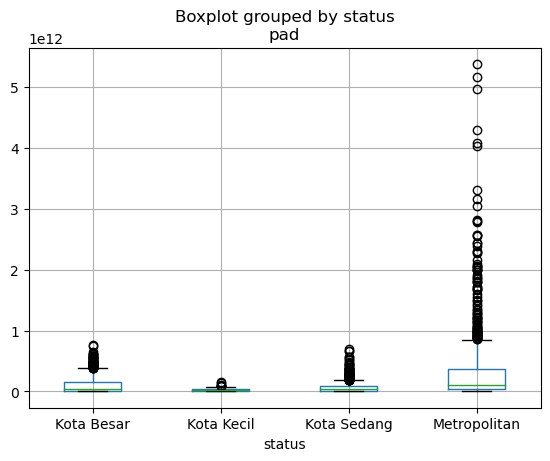

In [69]:
boxplot = df.boxplot(column=['pad'], by='status')

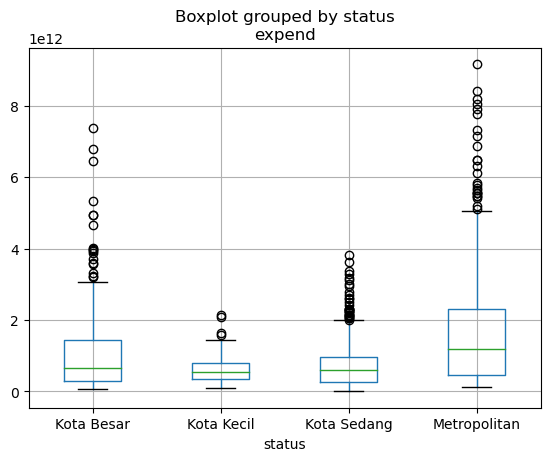

In [70]:
boxplot = df.boxplot(column=['expend'], by='status')

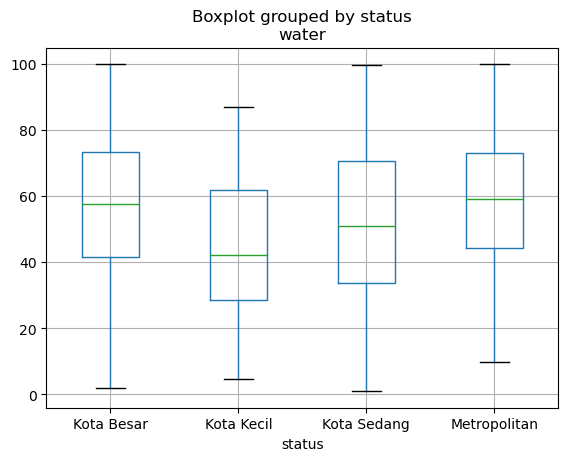

In [71]:
boxplot = df.boxplot(column=['water'], by='status')

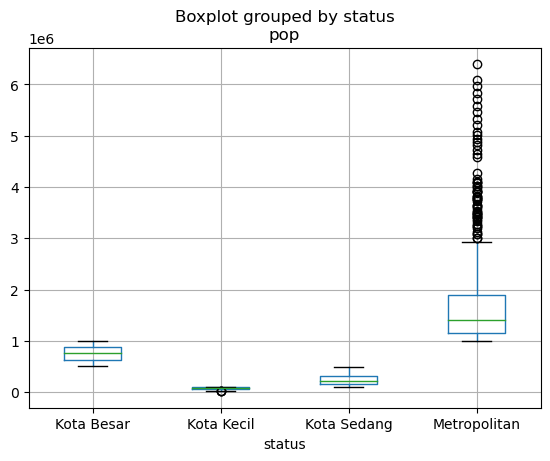

In [72]:
boxplot = df.boxplot(column=['pop'], by='status')

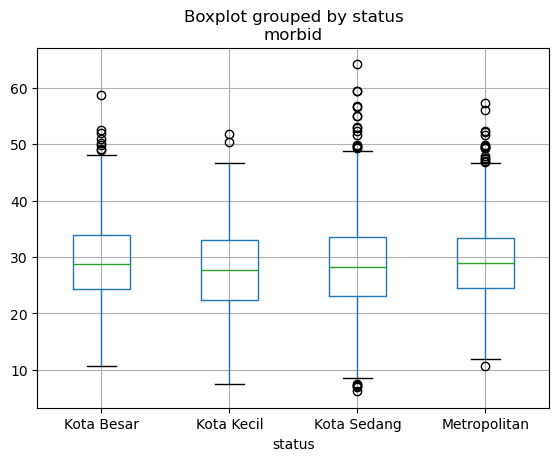

In [73]:
boxplot = df.boxplot(column=['morbid'], by='status')

In [74]:
df.columns

Index(['Unnamed: 0', 'id', 'year', 'water', 'expend', 'morbid', 'area', 'pop',
       'pad', 'daerah', 'tingkat', 'logpop', 'logpad', 'logarea', 'status'],
      dtype='object')

In [75]:
df.columns

Index(['Unnamed: 0', 'id', 'year', 'water', 'expend', 'morbid', 'area', 'pop',
       'pad', 'daerah', 'tingkat', 'logpop', 'logpad', 'logarea', 'status'],
      dtype='object')

In [76]:
df['logexpend'] = np.log(df['expend'])

In [77]:
df.isna().sum()

Unnamed: 0    0
id            0
year          0
water         0
expend        0
morbid        0
area          0
pop           0
pad           0
daerah        0
tingkat       0
logpop        0
logpad        0
logarea       0
status        0
logexpend     0
dtype: int64

# Modelling

## Data Splitting

In [78]:
# X = df.drop(['water','id','expend'],axis=1)
# y = df['water']

X = df[['logpop','logarea','logexpend','year','morbid','daerah','tingkat','status']]
y = df['water']



In [79]:
X

,logpop,logarea,logexpend,year,morbid,daerah,tingkat,status
0,12.663181,8.690978,25.847072,1996,17.11,Bengkulu Selatan,Kab.,Kota Sedang
1,12.668548,8.690978,25.970532,1997,17.54,Bengkulu Selatan,Kab.,Kota Sedang
2,12.672633,8.690978,25.886287,1998,23.03,Bengkulu Selatan,Kab.,Kota Sedang
3,12.675451,8.690978,25.834981,1999,15.82,Bengkulu Selatan,Kab.,Kota Sedang
4,12.823089,8.690978,25.890304,2000,20.42,Bengkulu Selatan,Kab.,Kota Sedang
...,...,...,...,...,...,...,...,...
4745,12.988901,8.274263,27.796754,2016,25.04,Way Kanan,Kab.,Kota Sedang
4746,12.998889,8.274263,27.931660,2017,30.87,Way Kanan,Kab.,Kota Sedang
4747,13.008328,8.274263,28.037216,2018,34.80,Way Kanan,Kab.,Kota Sedang
4748,13.017245,8.274263,27.968326,2019,31.26,Way Kanan,Kab.,Kota Sedang


In [80]:
y

0       12.99
1       14.60
2       13.99
3        8.20
4        9.01
        ...  
4745    38.02
4746    17.79
4747    27.24
4748    34.52
4749    42.02
Name: water, Length: 4750, dtype: float64

In [81]:
groups = df['id']
groups

0       ID.BE.BS
1       ID.BE.BS
2       ID.BE.BS
3       ID.BE.BS
4       ID.BE.BS
          ...   
4745    ID.LA.WK
4746    ID.LA.WK
4747    ID.LA.WK
4748    ID.LA.WK
4749    ID.LA.WK
Name: id, Length: 4750, dtype: object

In [82]:
# import numpy as np
# from sklearn.model_selection import GroupShuffleSplit

In [83]:
df.to_csv('airbersih.csv',index=False)

# Mulai Dari Sini

In [84]:
df = pd.read_csv('/Users/yudhapratama/Documents/Bahan Kuliah/UrbanAnalytics/airbersih.csv')

In [85]:
df.describe()

,Unnamed: 0,year,water,expend,morbid,area,pop,pad,logpop,logpad,logarea,logexpend
count,4750.000000,4750.000000,4750.000000,4.750000e+03,4750.000000,4750.000000,4.750000e+03,4.750000e+03,4750.000000,4750.000000,4750.000000,4750.000000
mean,6528.065474,2008.793895,54.858373,9.749613e+11,28.958404,4160.140455,7.540481e+05,1.355085e+11,13.112340,24.534544,7.227438,27.215833
std,2703.145698,6.996363,21.821467,9.355885e+11,7.517717,7618.078225,7.110925e+05,3.012936e+11,0.964640,1.551544,1.674509,0.905668
min,1550.000000,1996.000000,0.940000,2.303085e+09,6.190000,12.000000,1.338500e+04,3.985110e+08,9.501890,19.803246,2.484907,21.557516
25%,4317.250000,2003.000000,38.410000,3.180296e+11,23.870000,775.987500,2.181388e+05,1.615406e+10,12.292887,23.505437,6.654136,26.485410
50%,6500.500000,2009.000000,55.125000,6.993678e+11,28.595000,1521.880000,5.733555e+05,4.792337e+10,13.259261,24.592869,7.327702,27.273443
75%,8761.750000,2015.000000,71.987500,1.288502e+12,33.660000,3921.630000,1.039295e+06,1.398324e+11,13.854053,25.663710,8.274263,27.884502
max,11564.000000,2020.000000,100.000000,9.162656e+12,64.210000,91027.000000,6.398000e+06,5.381920e+12,15.671496,29.314066,11.418911,29.846157


In [86]:
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, TimeSeriesSplit

X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,  
    test_size=0.2,
    shuffle=True)

In [87]:
X_train

,logpop,logarea,logexpend,year,morbid,daerah,tingkat,status
3469,12.605795,8.005187,27.802952,2015,48.74,Barito Kuala,Kab.,Kota Sedang
2619,13.901757,6.576233,28.446297,2016,32.50,Mojokerto,Kab.,Metropolitan
1630,13.677754,6.052442,28.354535,2019,40.85,Kudus,Kab.,Kota Besar
4712,13.491297,8.958134,26.277416,2003,16.46,Tulang Bawang,Kab.,Kota Besar
4542,12.827098,8.507224,25.527907,2001,14.94,Lampung Barat,Kab.,Kota Sedang
...,...,...,...,...,...,...,...,...
3024,13.844098,7.552237,26.355133,1996,27.31,Tuban,Kab.,Metropolitan
2159,14.209915,8.662678,25.961008,1998,29.03,Banyuwangi,Kab.,Metropolitan
3013,13.423333,7.045097,27.410511,2010,30.04,Trenggalek,Kab.,Kota Besar
394,12.106053,4.376888,26.887570,2010,27.40,Gorontalo,Kota,Kota Sedang


## Model Prep

In [92]:
#Transform
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import category_encoders as ce
from sklearn.preprocessing import RobustScaler

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost.sklearn import XGBRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV, KFold

from sklearn.pipeline import Pipeline

In [93]:
transformer = ColumnTransformer(
    transformers=[
        ('kategorikal', OneHotEncoder(drop='first'), ['year','status','tingkat']),
        ('Binary',ce.BinaryEncoder(),['daerah'])
    ],remainder='passthrough'
)

scaler = RobustScaler()

In [94]:
# Define algoritma yang digunakan
lr = LinearRegression()
knn = KNeighborsRegressor()
dt = DecisionTreeRegressor(random_state=1)
rf = RandomForestRegressor(random_state=1)
xgb = XGBRegressor(random_state=1)

models = [lr,knn,dt,rf,xgb]
          
score_rmse = []
nilai_mean_rmse = []
nilai_std_rmse = []

score_mae = []
nilai_mean_mae = []
nilai_std_mae = []

score_mape = []
nilai_mean_mape = []
nilai_std_mape = []

In [95]:
# Mencari algoritma terbaik berdasarkan tiap metrics
for i in models:
    
    crossval = KFold(n_splits=5, shuffle=True, random_state=1)

    estimator = Pipeline([
        ('preprocessing', transformer),
        ('scaler', scaler),
        ('model', i)
    ])

    # RMSE
    model_cv_rmse = cross_val_score(
        estimator, 
        X_train, 
        y_train, 
        cv=crossval, 
        scoring='neg_root_mean_squared_error', 
        error_score='raise'
        )

    print(model_cv_rmse, i)

    score_rmse.append(model_cv_rmse)
    nilai_mean_rmse.append(model_cv_rmse.mean())
    nilai_std_rmse.append(model_cv_rmse.std())

    # MAE
    model_cv_mae = cross_val_score(
        estimator, 
        X_train, 
        y_train, 
        cv=crossval, 
        scoring='neg_mean_absolute_error', 
        error_score='raise'
        )

    print(model_cv_mae, i)

    score_mae.append(model_cv_mae)
    nilai_mean_mae.append(model_cv_mae.mean())
    nilai_std_mae.append(model_cv_mae.std())

    # MAPE
    model_cv_mape = cross_val_score(
        estimator, 
        X_train, 
        y_train, 
        cv=crossval, 
        scoring='neg_mean_absolute_percentage_error', 
        error_score='raise'
        )

    print(model_cv_mape, i)

    score_mape.append(model_cv_mape)
    nilai_mean_mape.append(model_cv_mape.mean())
    nilai_std_mape.append(model_cv_mape.std())

[-14.65324333 -14.34664127 -14.7092465  -14.18700961 -14.34209677] LinearRegression()
[-11.3211313  -11.38245714 -11.69200436 -11.27963876 -11.41936484] LinearRegression()
[-0.30869943 -0.37404612 -0.40728618 -0.32373511 -0.35436435] LinearRegression()
[-10.77550367 -10.5385248  -10.34602304  -9.59922238 -10.00550501] KNeighborsRegressor()
[-8.08064474 -7.76686316 -7.93952368 -7.41277632 -7.53200526] KNeighborsRegressor()
[-0.21549986 -0.24087968 -0.25851818 -0.20218514 -0.20461179] KNeighborsRegressor()
[-13.33677604 -13.51311847 -13.14343032 -13.33862366 -12.7904054 ] DecisionTreeRegressor(random_state=1)
[-9.70575    -9.62581579 -9.23618421 -9.55851316 -8.97332895] DecisionTreeRegressor(random_state=1)
[-0.23350007 -0.26748647 -0.24747571 -0.24699919 -0.22790756] DecisionTreeRegressor(random_state=1)
[-9.6130066  -9.87268705 -9.71926938 -9.681849   -9.71898818] RandomForestRegressor(random_state=1)
[-7.22953711 -7.41392474 -7.64265237 -7.50957329 -7.37849526] RandomForestRegressor(r

In [96]:
# Evaluasi hasil dari 5 kandidat algoritma yang digunakan
pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regressor', 'DecisionTree Regressor', 'RandomForest Regressor', 'XGBoost Regressor'],
    'Mean_RMSE': nilai_mean_rmse,
    'Std_RMSE': nilai_std_rmse,
    'Mean_MAE': nilai_mean_mae,
    'Std_MAE': nilai_std_mae,
    'Mean_MAPE': nilai_mean_mape,
    'Std_MAPE': nilai_std_mape
})

,Model,Mean_RMSE,Std_RMSE,Mean_MAE,Std_MAE,Mean_MAPE,Std_MAPE
0,Linear Regression,-14.447647,0.199990,-11.418919,0.144822,-0.353626,0.035239
1,KNN Regressor,-10.252956,0.412763,-7.746363,0.247671,-0.224339,0.021908
2,DecisionTree Regressor,-13.224471,0.246553,-9.419918,0.274409,-0.244674,0.013709
3,RandomForest Regressor,-9.721160,0.085101,-7.434837,0.137501,-0.218607,0.019222
4,XGBoost Regressor,-9.251486,0.235544,-7.102676,0.148244,-0.192476,0.013030


In [97]:
# Benchmark 2 model terbaik
models = {
    'XGB': XGBRegressor(random_state=1),
    'RandomForest': RandomForestRegressor(random_state=1)
}

score_rmse = []
score_mae = []
score_mape = []

# Prediksi pada test set
for i in models:

    model = Pipeline([
        ('preprocessing', transformer),
        ('scaler', scaler),
        ('model', models[i])
        ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score_rmse.append(np.sqrt(mean_squared_error(y_test, y_pred)))
    score_mae.append(mean_absolute_error(y_test, y_pred))
    score_mape.append(mean_absolute_percentage_error(y_test, y_pred))

score_before_tuning = pd.DataFrame({'RMSE': score_rmse, 'MAE': score_mae, 'MAPE': score_mape}, index=models.keys())
score_before_tuning

,RMSE,MAE,MAPE
XGB,8.940193,6.741769,0.207357
RandomForest,9.393900,7.212484,0.236239


## EXPORT MODEL

In [119]:
import pickle

estimator = Pipeline([
        ('preprocessing',transformer),
        ('scaler', scaler),
        ('model',XGBRegressor())
    ])
estimator.fit(X_train,y_train)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('kategorikal',
                                                  OneHotEncoder(drop='first'),
                                                  ['year', 'status',
                                                   'tingkat']),
                                                 ('Binary', BinaryEncoder(),
                                                  ['daerah'])])),
                ('scaler', RobustScaler()),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_b...
                              feature_types=None, gamma=None, gpu_id=None,
                              grow_policy=None, importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, n_estimators=100,
                              n_jobs=None, num_parallel_tree=None,
                              predictor=None, random_state=None, ...))])

In [120]:
pickle.dump(estimator, open('Model_AirBersih_.pkl', 'wb'))

In [5]:
cekdata = pd.read_csv('/Users/yudhapratama/Documents/Bahan Kuliah/UrbanAnalytics/updated.csv')
cekdata

,Unnamed: 0,id,year,water,morbid,area,pop,pad,daerah,tingkat,logpop,logpad,logarea,status,kabko,lat_x,long_x,lat_y,long_y
0,0,ID.BE.BS,1996,12.99,17.11,5949.00,315900.0,9.302870e+08,Bengkulu Selatan,Kab.,12.663181,20.651004,8.690978,Kota Sedang,KAB. BENGKULU SELATAN,-4.3248,103.0357,-4.3248,103.0357
1,1,ID.BE.BS,1997,14.60,17.54,5949.00,317600.0,1.448954e+09,Bengkulu Selatan,Kab.,12.668548,21.094108,8.690978,Kota Sedang,KAB. BENGKULU SELATAN,-4.3248,103.0357,-4.3248,103.0357
2,2,ID.BE.BS,1998,13.99,23.03,5949.00,318900.0,1.608408e+09,Bengkulu Selatan,Kab.,12.672633,21.198511,8.690978,Kota Sedang,KAB. BENGKULU SELATAN,-4.3248,103.0357,-4.3248,103.0357
3,3,ID.BE.BS,1999,8.20,15.82,5949.00,319800.0,1.686854e+09,Bengkulu Selatan,Kab.,12.675451,21.246131,8.690978,Kota Sedang,KAB. BENGKULU SELATAN,-4.3248,103.0357,-4.3248,103.0357
4,4,ID.BE.BS,2000,9.01,20.42,5949.00,370678.0,6.493360e+08,Bengkulu Selatan,Kab.,12.823089,20.291461,8.690978,Kota Sedang,KAB. BENGKULU SELATAN,-4.3248,103.0357,-4.3248,103.0357
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4600,4600,ID.LA.WK,2016,38.02,25.04,3921.63,437530.0,4.434695e+10,Way Kanan,Kab.,12.988901,24.515310,8.274263,Kota Sedang,KAB. WAY KANAN,-4.4964,104.5655,-4.4964,104.5655
4601,4601,ID.LA.WK,2017,17.79,30.87,3921.63,441922.0,4.955128e+10,Way Kanan,Kab.,12.998889,24.626274,8.274263,Kota Sedang,KAB. WAY KANAN,-4.4964,104.5655,-4.4964,104.5655
4602,4602,ID.LA.WK,2018,27.24,34.80,3921.63,446113.0,5.676499e+10,Way Kanan,Kab.,13.008328,24.762186,8.274263,Kota Sedang,KAB. WAY KANAN,-4.4964,104.5655,-4.4964,104.5655
4603,4603,ID.LA.WK,2019,34.52,31.26,3921.63,450109.0,6.235356e+10,Way Kanan,Kab.,13.017245,24.856087,8.274263,Kota Sedang,KAB. WAY KANAN,-4.4964,104.5655,-4.4964,104.5655
